In [1]:

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torchvision.models import resnet18
from torch.utils.data import DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cuda


In [2]:

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=2
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))


100%|██████████| 170M/170M [53:37<00:00, 53.0kB/s]


Training images: 50000
Testing images: 10000


In [3]:

model = resnet18(weights=None)

model.conv1 = nn.Conv2d(
    3, 64,
    kernel_size=3,
    stride=1,
    padding=1,
    bias=False
)

model.maxpool = nn.Identity()

model.fc = nn.Linear(
    model.fc.in_features, 10
)

model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("ResNet-18 model created successfully!")


ResNet-18 model created successfully!


In [4]:

epochs = 5

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Loss: {running_loss / total:.4f} | "
        f"Training Accuracy: {100 * correct / total:.2f}%"
    )


Epoch 1/5 | Loss: 1.1961 | Training Accuracy: 56.91%
Epoch 2/5 | Loss: 0.7102 | Training Accuracy: 74.93%
Epoch 3/5 | Loss: 0.5295 | Training Accuracy: 81.56%
Epoch 4/5 | Loss: 0.4103 | Training Accuracy: 85.69%
Epoch 5/5 | Loss: 0.2947 | Training Accuracy: 89.66%


In [5]:

model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

baseline_accuracy = 100 * correct / total

print(f"Clean CIFAR-10 Test Accuracy: {baseline_accuracy:.2f}%")


Clean CIFAR-10 Test Accuracy: 76.75%


In [6]:

torch.save(
    model.state_dict(),
    "resnet18_cifar10_baseline.pth"
)

print("Model saved successfully!")


Model saved successfully!


In [7]:

import numpy as np

# CIFAR-10 normalization values
mean = torch.tensor(
    [0.4914, 0.4822, 0.4465],
    device=device
).view(1, 3, 1, 1)

std = torch.tensor(
    [0.2470, 0.2435, 0.2616],
    device=device
).view(1, 3, 1, 1)

# Five Gaussian noise levels
noise_levels = [0.00, 0.05, 0.10, 0.15, 0.20]

noise_results = {}

model.eval()

for noise_level in noise_levels:
    correct = 0
    total = 0

    # Same random noise sequence for reproducibility
    generator = torch.Generator(device="cpu")
    generator.manual_seed(42)

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            # Convert normalized images back to [0, 1]
            original_images = images * std + mean

            # Add Gaussian noise
            noise = torch.randn(
                original_images.shape,
                generator=generator
            ).to(device) * noise_level

            noisy_images = torch.clamp(
                original_images + noise, 0, 1
            )

            # Normalize again for ResNet-18
            noisy_images = (noisy_images - mean) / std

            outputs = model(noisy_images)
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    accuracy = 100 * correct / total
    noise_results[noise_level] = accuracy

    print(
        f"Noise Level: {noise_level:.2f} | "
        f"Test Accuracy: {accuracy:.2f}%"
    )


Noise Level: 0.00 | Test Accuracy: 76.75%
Noise Level: 0.05 | Test Accuracy: 69.45%
Noise Level: 0.10 | Test Accuracy: 49.53%
Noise Level: 0.15 | Test Accuracy: 33.35%
Noise Level: 0.20 | Test Accuracy: 22.48%


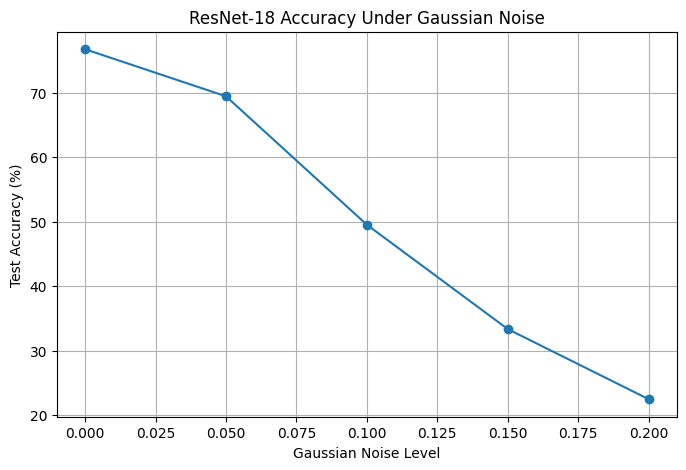

In [8]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    list(noise_results.keys()),
    list(noise_results.values()),
    marker="o"
)

plt.xlabel("Gaussian Noise Level")
plt.ylabel("Test Accuracy (%)")
plt.title("ResNet-18 Accuracy Under Gaussian Noise")
plt.grid(True)

plt.savefig("gaussian_noise_accuracy.png", dpi=300)
plt.show()


In [9]:

import torch.nn.functional as F

# Confidence thresholds
thresholds = [0.50, 0.60, 0.70, 0.80, 0.90]

# Store deferral results
deferral_results = {}

model.eval()

for noise_level in noise_levels:
    confidence_scores = []

    generator = torch.Generator(device="cpu")
    generator.manual_seed(42)

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)

            # Convert images back to [0, 1]
            original_images = images * std + mean

            # Add Gaussian noise
            noise = torch.randn(
                original_images.shape,
                generator=generator
            ).to(device) * noise_level

            noisy_images = torch.clamp(
                original_images + noise, 0, 1
            )

            # Normalize images again
            noisy_images = (noisy_images - mean) / std

            # Get model predictions
            outputs = model(noisy_images)

            # Calculate confidence
            probabilities = F.softmax(outputs, dim=1)
            confidence = probabilities.max(dim=1).values

            confidence_scores.extend(
                confidence.cpu().tolist()
            )

    confidence_scores = torch.tensor(confidence_scores)
    deferral_results[noise_level] = {}

    for threshold in thresholds:

        # Count low-confidence predictions
        deferred = confidence_scores < threshold

        deferral_rate = deferred.float().mean().item() * 100

        deferral_results[noise_level][threshold] = deferral_rate

        print(
            f"Noise: {noise_level:.2f} | "
            f"Threshold: {threshold:.2f} | "
            f"Deferral Rate: {deferral_rate:.2f}%"
        )

    print("--------------------------")


Noise: 0.00 | Threshold: 0.50 | Deferral Rate: 5.15%
Noise: 0.00 | Threshold: 0.60 | Deferral Rate: 11.62%
Noise: 0.00 | Threshold: 0.70 | Deferral Rate: 17.96%
Noise: 0.00 | Threshold: 0.80 | Deferral Rate: 24.96%
Noise: 0.00 | Threshold: 0.90 | Deferral Rate: 35.08%
--------------------------
Noise: 0.05 | Threshold: 0.50 | Deferral Rate: 9.07%
Noise: 0.05 | Threshold: 0.60 | Deferral Rate: 17.05%
Noise: 0.05 | Threshold: 0.70 | Deferral Rate: 24.76%
Noise: 0.05 | Threshold: 0.80 | Deferral Rate: 34.08%
Noise: 0.05 | Threshold: 0.90 | Deferral Rate: 45.13%
--------------------------
Noise: 0.10 | Threshold: 0.50 | Deferral Rate: 16.00%
Noise: 0.10 | Threshold: 0.60 | Deferral Rate: 27.35%
Noise: 0.10 | Threshold: 0.70 | Deferral Rate: 38.36%
Noise: 0.10 | Threshold: 0.80 | Deferral Rate: 49.34%
Noise: 0.10 | Threshold: 0.90 | Deferral Rate: 63.12%
--------------------------
Noise: 0.15 | Threshold: 0.50 | Deferral Rate: 19.66%
Noise: 0.15 | Threshold: 0.60 | Deferral Rate: 32.80%
Noi

In [10]:

import torch.nn.functional as F
import pandas as pd

human_error_rates = [0.00, 0.05, 0.10, 0.20]
system_results = []

model.eval()

for noise_level in noise_levels:
    all_confidences = []
    all_correct = []

    generator = torch.Generator(device="cpu")
    generator.manual_seed(42)

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            original_images = images * std + mean

            noise = torch.randn(
                original_images.shape,
                generator=generator
            ).to(device) * noise_level

            noisy_images = torch.clamp(
                original_images + noise, 0, 1
            )

            noisy_images = (noisy_images - mean) / std

            outputs = model(noisy_images)
            probabilities = F.softmax(outputs, dim=1)

            confidence, predictions = probabilities.max(dim=1)

            all_confidences.append(confidence.cpu())
            all_correct.append((predictions == labels).cpu())

    all_confidences = torch.cat(all_confidences)
    all_correct = torch.cat(all_correct)

    ai_accuracy = all_correct.float().mean().item() * 100
    total_images = len(all_correct)

    for threshold in thresholds:
        deferred = all_confidences < threshold
        accepted = ~deferred

        deferred_count = deferred.sum().item()
        deferral_rate = deferred_count / total_images * 100

        ai_correct_accepted = all_correct[accepted].sum().item()

        for error_rate in human_error_rates:
            # Expected correct decisions by simulated human
            human_correct = deferred_count * (1 - error_rate)

            # Expected combined system accuracy
            system_accuracy = (
                (ai_correct_accepted + human_correct)
                / total_images * 100
            )

            system_results.append({
                "Noise": noise_level,
                "Threshold": threshold,
                "Human Error": error_rate,
                "AI Accuracy (%)": round(ai_accuracy, 2),
                "Deferral Rate (%)": round(deferral_rate, 2),
                "System Accuracy (%)": round(system_accuracy, 2)
            })

results_df = pd.DataFrame(system_results)

print(results_df.to_string(index=False))

results_df.to_csv("system_accuracy_results.csv", index=False)

print("\nResults saved successfully!")


 Noise  Threshold  Human Error  AI Accuracy (%)  Deferral Rate (%)  System Accuracy (%)
  0.00        0.5         0.00            76.75               5.15                80.19
  0.00        0.5         0.05            76.75               5.15                79.93
  0.00        0.5         0.10            76.75               5.15                79.67
  0.00        0.5         0.20            76.75               5.15                79.16
  0.00        0.6         0.00            76.75              11.62                83.84
  0.00        0.6         0.05            76.75              11.62                83.26
  0.00        0.6         0.10            76.75              11.62                82.68
  0.00        0.6         0.20            76.75              11.62                81.52
  0.00        0.7         0.00            76.75              17.96                87.04
  0.00        0.7         0.05            76.75              17.96                86.14
  0.00        0.7         0.10  

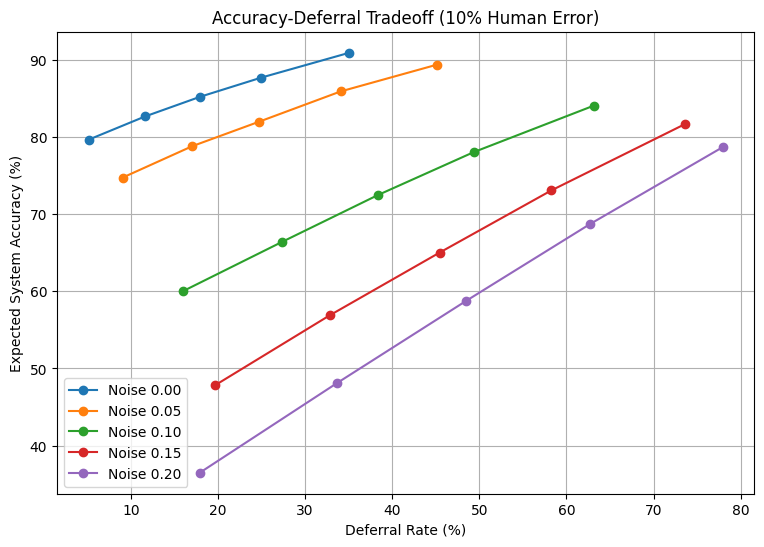

In [11]:

import matplotlib.pyplot as plt

# Compare system accuracy and deferral rate
# at different noise levels for 10% human error

plt.figure(figsize=(9, 6))

for noise_level in noise_levels:
    data = results_df[
        (results_df["Noise"] == noise_level) &
        (results_df["Human Error"] == 0.10)
    ].sort_values("Deferral Rate (%)")

    plt.plot(
        data["Deferral Rate (%)"],
        data["System Accuracy (%)"],
        marker="o",
        label=f"Noise {noise_level:.2f}"
    )

plt.xlabel("Deferral Rate (%)")
plt.ylabel("Expected System Accuracy (%)")
plt.title("Accuracy-Deferral Tradeoff (10% Human Error)")
plt.legend()
plt.grid(True)

plt.savefig("accuracy_deferral_tradeoff.png", dpi=300)
plt.show()
